In [80]:
import geopandas
import pandas as pd

In [81]:
berlin_gdf = geopandas.read_file("BerlinDistricts.gdb")
berlin_gdf = berlin_gdf.to_crs("EPSG:4326")
berlin_gdf = berlin_gdf.set_index("name")
berlin_gdf

,schlüssel,gdf,SHAPE_Length,SHAPE_Area,geometry
name,,,,,
Rahnsdorf,110000090912,21442809.0,50943.190174,5.761442e+07,"MULTIPOLYGON (((13.70385 52.45481, 13.70461 52..."
Rudow,110000080804,11818287.0,27441.756160,3.171547e+07,"MULTIPOLYGON (((13.47869 52.44274, 13.47875 52..."
Charlottenburg-Nord,110000040406,6199488.0,18719.891497,1.673023e+07,"MULTIPOLYGON (((13.27196 52.54939, 13.27209 52..."
Siemensstadt,110000050503,5663969.0,21852.474844,1.528409e+07,"MULTIPOLYGON (((13.24096 52.55602, 13.24113 52..."
Hakenfelde,110000050507,20381270.0,37928.645962,5.508595e+07,"MULTIPOLYGON (((13.20221 52.58804, 13.20253 52..."
...,...,...,...,...,...
Wannsee,110000060607,23735618.0,52313.210225,6.370469e+07,"MULTIPOLYGON (((13.16655 52.44252, 13.16723 52..."
Wedding,110000010105,9245378.0,23763.290521,2.496165e+07,"MULTIPOLYGON (((13.3569 52.56202, 13.35709 52...."
Lichterfelde,110000060602,18226316.0,36848.267479,4.893303e+07,"MULTIPOLYGON (((13.3071 52.45893, 13.30689 52...."


In [109]:
stations_df = pd.read_csv("PublicTransitDataset/stations.csv")
stations_df

,stop_id,stop_name,typ,standort,in_linien,wikidata_id
0,19460,Adlershof,s-bahn,"52.434722222222,13.541388888889","['KBS 100a', 'KBS 100c']",Q323551
1,19461,Akazienallee,omnibus,"52.47849809201335, 13.607179083668733",['D'],NaN
2,19462,Alexanderplatz,omnibus,"52.52005246558073, 13.413957243449447","['1', '9']",NaN
3,19463,Alexanderplatz,s-bahn,"52.521388888889,13.411944444444","['KBS 100c', 'KBS 101']",Q111324700
4,19464,Alexanderplatz,straßenbahn,"52.5219449,13.4143847","['60', '64', '65', '72', '73']",Q65548996
...,...,...,...,...,...,...
19753,19892663,kantstr.,autobus,"52.50531710941182, 13.331624484752632",['60'],NaN
19754,19892664,katzbachstr.,autobus,"52.49157231856929, 13.376684416851326",['19'],NaN
19755,19892665,neuhoferstr.,autobus,"52.411694901653036, 13.503489970696608",['58'],NaN
19756,19892666,Öschebronnerweg,autobus,"52.61154475375042, 13.337669105320359",['20'],NaN


In [98]:
longlatlist = list()
stop_ids = list()
stop_names = list()
typs = list()
in_liniens = list()
wikidata_ids = list()
for i, item in enumerate(stations_df["standort"]):
    longlatlist.append(item.split(","))
    stop_ids.append(stations_df["stop_id"][i])
    stop_names.append(stations_df["stop_name"][i])
    typs.append(stations_df["typ"][i])
    in_liniens.append(stations_df["in_linien"][i])
    wikidata_ids.append(stations_df["wikidata_id"][i])
#print(longlatlist)

#for item in longlatlist:
    #item.insert(2,item[0])
    #item.remove(item[0])
    #print(item)
longlist = list()
latlist = list()
for item in longlatlist:
    latlist.append(item[0])
    longlist.append(item[1])

In [84]:
print(longlatlist)
print(longlist)
print(latlist)

[['52.434722222222', '13.541388888889'], ['52.47849809201335', ' 13.607179083668733'], ['52.52005246558073', ' 13.413957243449447'], ['52.521388888889', '13.411944444444'], ['52.5219449', '13.4143847'], ['52.5214', '13.4119'], ['52.51778540833277', ' 13.418077932963259'], ['52.508805788386496', ' 13.558724778261455'], ['52.51072943298707', ' 13.504877027235766'], ['52.50914093654053', ' 13.518129930582422'], ['52.50517404169193', ' 13.581539359412261'], ['52.522953428732706', ' 13.363110996619637'], ['52.512205003004254', ' 13.20098769648865'], ['52.511300751384205', ' 13.434689302904747'], ['52.50992342587209', ' 13.433401993102558'], ['52.49174753133871', ' 13.457760339630582'], ['52.4558167657369', ' 13.558133104178587'], ['52.503055555556', '13.381944444444'], ['52.50453275122', ' 13.382326534592197'], ['52.50449054956299', ' 13.382289924849571'], ['52.455498340147045', ' 13.375619638525905'], ['52.44680180814698', ' 13.360708029669821'], ['52.3914', '13.0928'], ['52.55227848989899

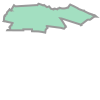

In [91]:

Kreuzberg = berlin_gdf.loc["Kreuzberg", "geometry"]
Kreuzberg

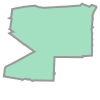

In [93]:
Wilmersdorf = berlin_gdf.loc["Wilmersdorf", "geometry"]
Wilmersdorf

In [87]:
pointdataframe = pd.DataFrame({'longitude': longlist, 'latitude': latlist})
examplepoints = geopandas.points_from_xy(pointdataframe.longitude, pointdataframe.latitude, crs="EPSG:4326")
examplepoints = examplepoints.to_crs("EPSG:4326")

In [105]:
Kreuzberg_points = list()
Kreuzberg_longlatlist = list()
Kreuzberg_stop_ids = list()
Kreuzberg_stop_names = list()
Kreuzberg_typs = list()
Kreuzberg_in_liniens = list()
Kreuzberg_wikidata_ids = list()
for i, point in enumerate(examplepoints):
    if Kreuzberg.contains(point):
        print(point)
        Kreuzberg_points.append(point)
        Kreuzberg_longlatlist.append(longlatlist[i])
        Kreuzberg_stop_ids.append(stop_ids[i])
        Kreuzberg_stop_names.append(stop_names[i])
        Kreuzberg_typs.append(typs[i])
        Kreuzberg_in_liniens.append(in_liniens[i])
        Kreuzberg_wikidata_ids.append(wikidata_ids[i])

POINT (13.381944444444 52.503055555556)
POINT (13.382326534592197 52.50453275122)
POINT (13.382289924849571 52.50449054956299)
POINT (13.400299112902015 52.490331369885155)
POINT (13.389323838894562 52.49508128500466)
POINT (13.388333333333 52.493888888889)
POINT (13.387758933826115 52.49289753565708)
POINT (13.407771678016932 52.48915625862438)
POINT (13.407777777778 52.489444444444)
POINT (13.37409 52.49952)
POINT (13.396394305880412 52.49118173025337)
POINT (13.395555555556 52.491388888889)
POINT (13.428 52.4992)
POINT (13.391726405887525 52.49794750808006)
POINT (13.391111111111 52.497777777778)
POINT (13.398277044768834 52.50710477957293)
POINT (13.390611111111 52.505897222222)
POINT (13.418055555556 52.499166666667)
POINT (13.431947867729278 52.505757518022115)
POINT (13.394408948438224 52.50113590948542)
POINT (13.410833333333 52.503611111111)
POINT (13.406111111111 52.498333333333)
POINT (13.441502603146748 52.50089071846621)
POINT (13.441666666667 52.500833333333)
POINT (13.42

In [107]:
Kreuzberg_stations_df = pd.DataFrame({'stop_id':Kreuzberg_stop_ids, 'stop_name':Kreuzberg_stop_names, 'typ':Kreuzberg_typs, 'location':Kreuzberg_longlatlist, 'point':Kreuzberg_points, "in_linien":Kreuzberg_in_liniens, "wikidata_id":Kreuzberg_wikidata_ids})
Kreuzberg_stations_df

,stop_id,stop_name,typ,location,point,in_linien,wikidata_id
0,194617,Anhalter Bahnhof,s-bahn,"[52.503055555556, 13.381944444444]",POINT (13.381944444444 52.503055555556),"['KBS 103', 'KBS 104a', 'KBS 105a']",Q111324573
1,194618,Anhalter Bahnhof,straßenbahn,"[52.50453275122, 13.382326534592197]",POINT (13.382326534592197 52.50453275122),['1'],NaN
2,194619,Anhalter Bhf.,straßenbahn,"[52.50449054956299, 13.382289924849571]",POINT (13.382289924849571 52.50449054956299),['21'],NaN
3,194626,Baerwaldstr. Ecke Gneisenaustr.,straßenbahn,"[52.490331369885155, 13.400299112902015]",POINT (13.400299112902015 52.490331369885155),['99'],NaN
4,1946158,Franz-Mehringstr.,omnibus,"[52.49508128500466, 13.389323838894562]",POINT (13.389323838894562 52.49508128500466),['1'],NaN
...,...,...,...,...,...,...,...
717,19892573,Wilmsstr.,autobus,"[52.4952693941617, 13.404256096296391]",POINT (13.404256096296391 52.4952693941617),['28'],NaN
718,19892598,Wrangelstr.,autobus,"[52.50349055126274, 13.43002511023885]",POINT (13.43002511023885 52.50349055126274),['28'],NaN
719,19892607,Yorckstr.,autobus,"[52.49290342432449, 13.387649041870562]",POINT (13.387649041870562 52.49290342432449),['28'],NaN
720,19892609,Yorckstr.,u-bahn,"[52.493056, 13.370833]",POINT (13.370833 52.493056),['7'],Q12011022


In [112]:
Kreuzberg_stations_df.to_csv("FilteredDataset/Kreuzberg_stations.csv")

In [113]:
Wilmersdorf_points = list()
Wilmersdorf_longlatlist = list()
Wilmersdorf_stop_ids = list()
Wilmersdorf_stop_names = list()
Wilmersdorf_typs = list()
Wilmersdorf_in_liniens = list()
Wilmersdorf_wikidata_ids = list()
for i, point in enumerate(examplepoints):
    if Wilmersdorf.contains(point):
        print(point)
        Wilmersdorf_points.append(point)
        Wilmersdorf_longlatlist.append(longlatlist[i])
        Wilmersdorf_stop_ids.append(stop_ids[i])
        Wilmersdorf_stop_names.append(stop_names[i])
        Wilmersdorf_typs.append(typs[i])
        Wilmersdorf_in_liniens.append(in_liniens[i])
        Wilmersdorf_wikidata_ids.append(wikidata_ids[i])

POINT (13.3309375952067 52.487339334357976)
POINT (13.314317300484289 52.49032472677901)
POINT (13.314444444444 52.490277777778)
POINT (13.313236111111 52.479808333333)
POINT (13.300864203881337 52.48810038121649)
POINT (13.325 52.493888888889)
POINT (13.331062759957598 52.487334054837376)
POINT (13.330862745431165 52.4959470039677)
POINT (13.3347 52.4983)
POINT (13.314444444444 52.473333333333)
POINT (13.312441666667 52.479672222222)
POINT (13.328525 52.477658333333)
POINT (13.319441513653306 52.49218319473536)
POINT (13.320423728961352 52.48648462511159)
POINT (13.331006268658216 52.48733987181299)
POINT (13.322515759458744 52.48648936437959)
POINT (13.301391593074351 52.488282179186875)
POINT (13.31144106616216 52.479600994756)
POINT (13.320415858318503 52.48647889641657)
POINT (13.331014163134173 52.48733630342845)
POINT (13.331070877561359 52.48736505635926)
POINT (13.32860278411238 52.478678991134835)
POINT (13.328566193541166 52.4777799057296)
POINT (13.319243498954092 52.492105

In [114]:
Wilmersdorf_stations_df = pd.DataFrame({'stop_id':Wilmersdorf_stop_ids, 'stop_name':Wilmersdorf_stop_names, 'typ':Wilmersdorf_typs, 'location':Wilmersdorf_longlatlist, 'point':Wilmersdorf_points, "in_linien":Wilmersdorf_in_liniens, "wikidata_id":Wilmersdorf_wikidata_ids})
Wilmersdorf_stations_df

,stop_id,stop_name,typ,location,point,in_linien,wikidata_id
0,194645,Berlinerstr. Ecke Kaiserallee,straßenbahn,"[52.487339334357976, 13.3309375952067]",POINT (13.3309375952067 52.487339334357976),['3'],NaN
1,1946147,Fehrbellinerplatz,straßenbahn,"[52.49032472677901, 13.314317300484289]",POINT (13.314317300484289 52.49032472677901),"['3', '62']",NaN
2,1946148,Fehrbellinerplatz,u-bahn,"[52.490277777778, 13.314444444444]",POINT (13.314444444444 52.490277777778),['A2'],Q663245
3,1946219,Heidelbergerplatz,u-bahn,"[52.479808333333, 13.313236111111]",POINT (13.313236111111 52.479808333333),['A2'],Q21777872
4,1946238,Hohenzollerndamm,straßenbahn,"[52.48810038121649, 13.300864203881337]",POINT (13.300864203881337 52.48810038121649),['62'],NaN
...,...,...,...,...,...,...,...
472,19892426,Uhlandstr.,autobus,"[52.49371867338476, 13.323534918277579]",POINT (13.323534918277579 52.49371867338476),['50'],NaN
473,19892454,Waghäuselerstr.,autobus,"[52.48391612851139, 13.330974926061291]",POINT (13.330974926061291 52.48391612851139),['74'],NaN
474,19892503,Weimarischestr.,autobus,"[52.48174499330689, 13.324245601196424]",POINT (13.324245601196424 52.48174499330689),['74'],NaN
475,19892541,Wiesbadenerstr.,autobus,"[52.472139703970726, 13.3143773020809]",POINT (13.3143773020809 52.472139703970726),"['1', '16', '86']",NaN


In [117]:
Wilmersdorf_stations_df.to_csv("FilteredDataset/Wilmersdorf_stations.csv")